In [50]:
import pandas as pd
import seaborn as sns

df=pd.read_csv("/content/heart.csv")

In [51]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [52]:
df.head(22)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


In [53]:
df.shape

(1025, 14)

In [54]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [55]:
df.duplicated().sum()

np.int64(723)

In [56]:
df=df.drop_duplicates()

In [57]:
df.duplicated().sum()

np.int64(0)

In [61]:
df.shape

(302, 14)

In [62]:
ls=["age", "trestbps",	"chol",	"thalach",  "oldpeak"]

In [63]:
import matplotlib.pyplot as plt

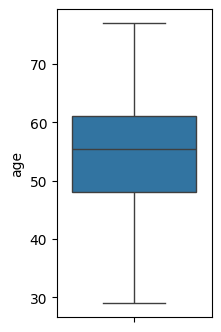

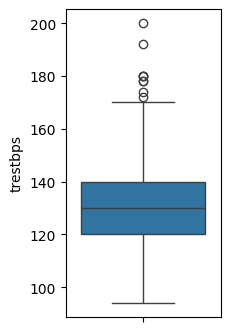

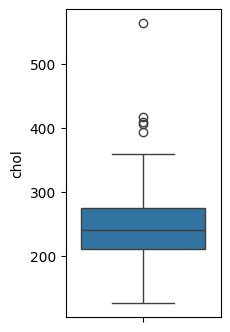

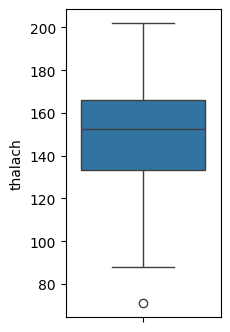

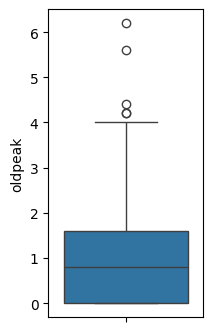

In [64]:
for i in ls:
  plt.figure(figsize=(2,4))
  sns.boxplot(df[i])

In [65]:
for i in ls:

  Q3 = df[i].quantile(0.75)
  Q1 = df[i].quantile(0.25)

  IQR = Q3-Q1

  UL = Q3+1.5*(IQR)
  LL = Q1-1.5*(IQR)

  df[i]=df[i].clip(LL,UL)


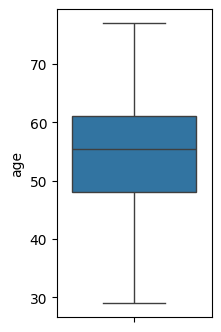

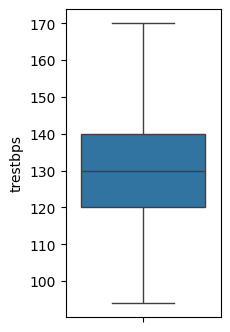

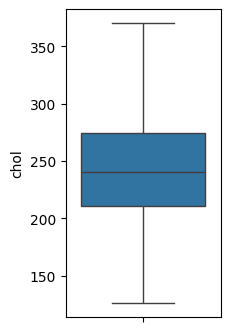

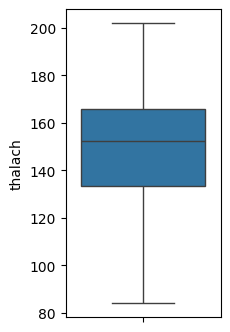

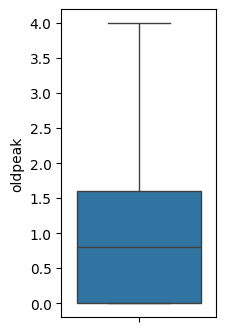

In [66]:
for i in ls:
  plt.figure(figsize=(2,4))
  sns.boxplot(df[i])

In [69]:
x=df.drop(columns=["target"])
y=df["target"]

In [70]:
x

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212.0,0,1,168.0,0,1.0,2,2,3
1,53,1,0,140,203.0,1,0,155.0,1,3.1,0,0,3
2,70,1,0,145,174.0,0,1,125.0,1,2.6,0,0,3
3,61,1,0,148,203.0,0,1,161.0,0,0.0,2,1,3
4,62,0,0,138,294.0,1,1,106.0,0,1.9,1,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,68,0,2,120,211.0,0,0,115.0,0,1.5,1,0,2
733,44,0,2,108,141.0,0,1,175.0,0,0.6,1,0,2
739,52,1,0,128,255.0,0,1,161.0,1,0.0,2,1,3
843,59,1,3,160,273.0,0,0,125.0,0,0.0,2,0,2


In [71]:
X_enc= pd.get_dummies(x, columns=["cp", "restecg", "slope", "thal"], drop_first=True, dtype=int)

In [73]:
X_enc

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1,cp_2,cp_3,restecg_1,restecg_2,slope_1,slope_2,thal_1,thal_2,thal_3
0,52,1,125,212.0,0,168.0,0,1.0,2,0,0,0,1,0,0,1,0,0,1
1,53,1,140,203.0,1,155.0,1,3.1,0,0,0,0,0,0,0,0,0,0,1
2,70,1,145,174.0,0,125.0,1,2.6,0,0,0,0,1,0,0,0,0,0,1
3,61,1,148,203.0,0,161.0,0,0.0,1,0,0,0,1,0,0,1,0,0,1
4,62,0,138,294.0,1,106.0,0,1.9,3,0,0,0,1,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,68,0,120,211.0,0,115.0,0,1.5,0,0,1,0,0,0,1,0,0,1,0
733,44,0,108,141.0,0,175.0,0,0.6,0,0,1,0,1,0,1,0,0,1,0
739,52,1,128,255.0,0,161.0,1,0.0,1,0,0,0,1,0,0,1,0,0,1
843,59,1,160,273.0,0,125.0,0,0.0,0,0,0,1,0,0,0,1,0,1,0


In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X_enc,y,test_size=0.2)

In [77]:
X_train.shape

(241, 19)

In [78]:
X_test.shape

(61, 19)

In [81]:
from sklearn.preprocessing import StandardScaler

SC = StandardScaler()
X_train= SC.fit_transform(X_train)
X_test= SC.transform(X_test)

In [82]:
X_train

array([[-1.04663103,  0.67216607, -0.97281789, ..., -0.22891428,
         0.92403796, -0.82073815],
       [-0.029542  , -1.48772757,  0.02859791, ..., -0.22891428,
         0.92403796, -0.82073815],
       [ 0.19647778,  0.67216607, -0.08921571, ...,  4.36844747,
        -1.08220662, -0.82073815],
       ...,
       [ 0.08346789, -1.48772757,  0.02859791, ..., -0.22891428,
         0.92403796, -0.82073815],
       [ 0.87453713, -1.48772757,  0.49985241, ..., -0.22891428,
         0.92403796, -0.82073815],
       [-0.029542  ,  0.67216607,  1.08892053, ..., -0.22891428,
        -1.08220662,  1.2184154 ]], shape=(241, 19))

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [83]:
from sklearn.linear_model import LogisticRegression

In [85]:
LR = LogisticRegression()


In [86]:
LR.fit(X_train, Y_train)

LogisticRegression()

In [88]:
Y_pred = LR.predict(X_test)

In [89]:
Y_pred

array([1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1])

In [102]:
accuracy_score(Y_test, Y_pred)

0.8688524590163934

In [103]:
precision_score(Y_test, Y_pred)


0.9090909090909091

In [104]:
recall_score(Y_test, Y_pred)

0.8571428571428571

In [105]:
f1_score(Y_test, Y_pred)

0.8823529411764706

In [90]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, Y_train)

knn_pred = knn.predict(X_test)

In [91]:
knn_pred

array([1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1])

In [106]:
accuracy_score(Y_test, knn_pred)

0.8524590163934426

In [107]:
precision_score(Y_test, knn_pred)

0.90625

In [108]:
recall_score(Y_test, knn_pred)

0.8285714285714286

In [109]:
f1_score(Y_test, knn_pred)

0.8656716417910447

In [92]:
from sklearn.svm import SVC

svm = SVC()

svm.fit(X_train, Y_train)

svm_pred = svm.predict(X_test)

In [93]:
svm_pred

array([1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1])

In [110]:
accuracy_score(Y_test, svm_pred)

0.8688524590163934

In [111]:

precision_score(Y_test, svm_pred)

0.9090909090909091

In [112]:
recall_score(Y_test, svm_pred)

0.8571428571428571

In [113]:

f1_score(Y_test, svm_pred)

0.8823529411764706

In [114]:
confusion_matrix(Y_test, Y_pred)

array([[23,  3],
       [ 5, 30]])

In [115]:
confusion_matrix(Y_test, knn_pred)

array([[23,  3],
       [ 6, 29]])

In [116]:
confusion_matrix(Y_test, svm_pred)

array([[23,  3],
       [ 5, 30]])

<Axes: >

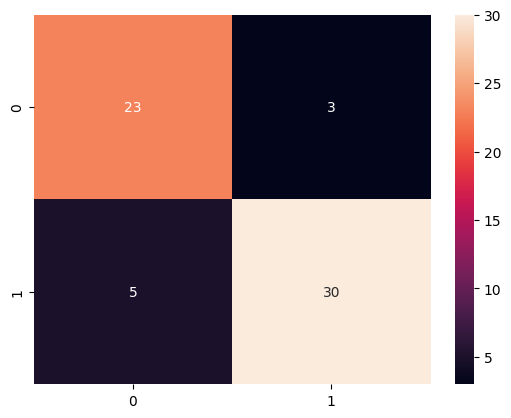

In [117]:
sns.heatmap(confusion_matrix(Y_test, Y_pred), annot=True, fmt="d")

<Axes: >

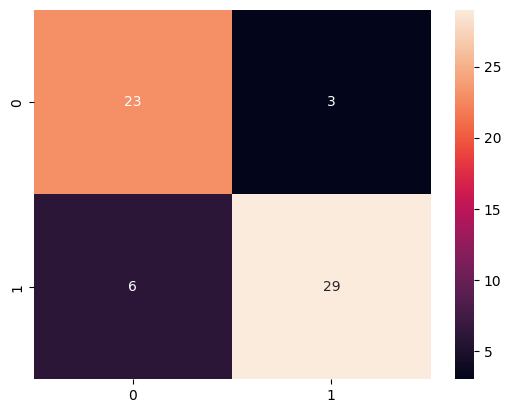

In [118]:
sns.heatmap(confusion_matrix(Y_test, knn_pred), annot=True, fmt="d")

<Axes: >

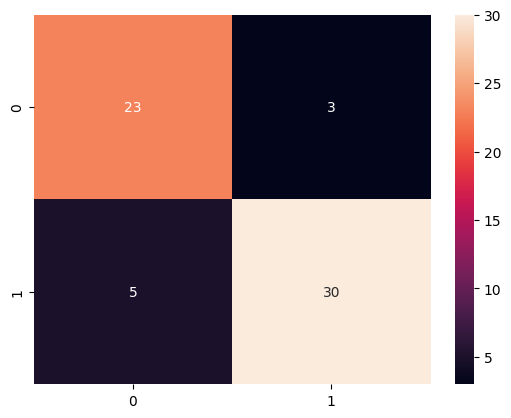

In [119]:
sns.heatmap(confusion_matrix(Y_test, svm_pred), annot=True, fmt="d")

Logistic Regression and SVM both performed well

I would choose Logistic Regression because it gives the same results as SVM and is easier to understand. It also detected more positive cases than KNN, which is important for heart disease prediction.